## Computational Homework 2, 2026

#### Due September 23

Unless expressly stated otherwise, please make sure your plot axes have labels and multiple lines on the same plot are explained in a legend.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy
from scipy.integrate import solve_ivp

plt.rcParams.update({'font.size':16, 'axes.labelsize':16})

#### Including friction in Lagrangian mechanics

<ol>
    <li>Assume a single particle moving in one dimension is subjected to a net <bf>conservative</bf> force \[ F = -\frac{\partial U}{\partial x} \] and a friction force $F_{\rm fric}$. Define the Lagrangian as \[\mathcal{L} =  \mathcal{T} - U \] and show that the appropriate modification to the Euler-Lagrange equation is \[ \frac{\partial \mathcal{L}}{\partial x} + F_{\rm fric} = \frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{x}}.\] Write out your solution step by step in a Markdown cell in this notebook (like this one). Markdown syntax is quite similar to LaTeX; see the <a href=https://www.markdownguide.org/basic-syntax/>Markdown guide</a>.</li>
</ol>

*Your answer here*

Newton's second law is

$$
m\ddot{x}=-\frac{\partial U}{\partial x}+F_{\rm fric}
$$

The Lagrangian is

$$
\mathcal{L}=\frac12m\dot{x}^2-U
$$


$$
\frac{\partial\mathcal{L}}{\partial x}
=-\frac{\partial U}{\partial x}
$$


$$
\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot{x}}
=
\frac{d}{dt}(m\dot{x})
=
m\ddot{x}
$$

Substituting Newton's second law gives

$$
\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot{x}}
=
\frac{\partial\mathcal{L}}{\partial x}+F_{\rm fric}
$$

Thus,

$$
\frac{\partial\mathcal{L}}{\partial x}+F_{\rm fric}
=
\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot{x}}
$$


#### Oscillations about an equilibrium point

Consider Example 7.6 in your textbook, the bead on the spinning wire. Equation 7.69 gives the equation of motion (EOM): $\ddot{\theta} = (\omega^2 \cos \theta - g/R) \sin \theta.$ While the EOM doesn't have an analytical solution, it can be solved numerically. The behavior of the system is determined by the ratio $\frac{\omega^2}{g/R}.$

<ol start=2>
    <li>Choose a value of $\frac{\omega^2}{g/R}$ that is much less than 1. Select a value of $R$ that is of order 1 meter. The exact number is up to you. Start the bead at a small displacement from the equilibrium position at the bottom of the hoop. The exact angle of your displacement is up to you. Use <tt>sympy</tt> to <em>numerically</em> solve your equation of motion to find $\theta(t)$ for 5 full rotations of the hoop. Plot your answer.</li>
    <li>Now pick a value of $\frac{\omega^2}{g/R}$ that is comfortably higher than 1. Again, start the bead at a small displacement from the bottom of the hoop. Use <tt>sympy</tt> to numerically find $\theta(t)$ for five rotations of the hoop and plot your answer. In a Markdown cell, explain how your answer differs from question 2.</li>
</ol>

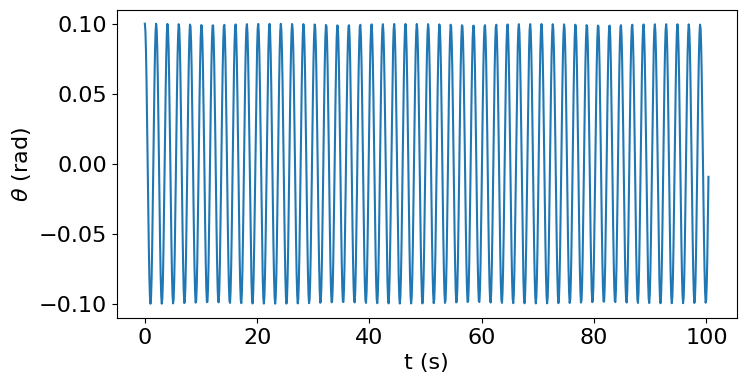

In [2]:
g = 9.8
R = 1
ratio= 0.01

omega = np.sqrt(ratio * g / R)

theta = sympy.symbols("theta", real=True)
theta_ddot = (omega**2*sympy.cos(theta) - g/R) *sympy.sin(theta)
acceleration = sympy.lambdify(theta, theta_ddot, "numpy")

def eom(t, y):
    return [y[1], acceleration(y[0])]

period = 2*np.pi / omega
t = np.linspace(0, 5 * period, 1000)

solution = solve_ivp(eom,[0, 5* period], [0.1, 0], t_eval=t)

plt.figure(figsize=(8, 4))
plt.plot(solution.t, solution.y[0])

plt.xlabel("t (s)")
plt.ylabel(r"$\theta$ (rad)")
plt.show()

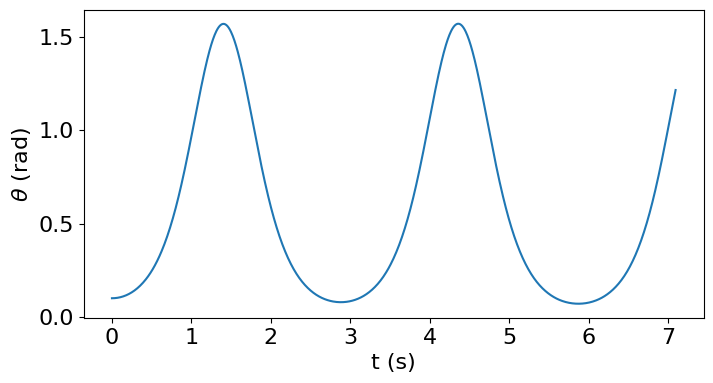

In [3]:
ratio = 2

omega = np.sqrt(ratio * g/R)

theta_ddot = (omega**2 * sympy.cos(theta) - g/R)*sympy.sin(theta)
acceleration = sympy.lambdify(theta, theta_ddot,"numpy")

period = 2*np.pi/omega
t = np.linspace(0, 5*period, 1000)

solution = solve_ivp(eom, [0, 5*period], [0.1, 0], t_eval=t)

plt.figure(figsize=(8, 4))
plt.plot(solution.t, solution.y[0])
plt.xlabel("t (s)")
plt.ylabel(r"$\theta$ (rad)")
plt.show()

Unlike the results in question 2, the bead no longer oscillates around the bottom of the hoop. When the ratio is greater than 1, the bottom becomes unstable, so the bead moves away from $\theta=0$ and oscillates around a new equilibrium position.


#### Testing <tt>sympy.calculus.euler.euler_equations</tt>

In Figure 7.12 of your textbook, a yoyo is represented by a cylinder of radius $R$ rolling down a string with negligible mass at angular speed $\omega$.

<ol start=4>
    <li>Write the Lagrangian for one generalized coordinate, the vertical distance of the string-cylinder contact point from the yoyo-er's hand, and try to use <tt>sympy.calculus.euler.euler_equations</tt> to find the Euler-Lagrange equation.</li>
    <li>Derive the Euler-Lagrange equation by hand. Does your solution match <tt>sympy</tt>'s solution? If <tt>sympy</tt> was unsuccesful at solving the Euler-Lagrange equation, how might you improve your calculation? Remember that, like any physicist, a computer algebra system likes to be fed information in the simplest form possible.</li>
</ol>

In [6]:
t=sympy.symbols("t", real=True)
m,R,g = sympy.symbols("m R g", positive=True)
x = sympy.Function("x")(t)

I = sympy.Rational(1, 2)*m* R**2
omega = x.diff(t) / R

T = sympy.Rational(1, 2)*m*x.diff(t)**2+sympy.Rational(1, 2)*I*omega**2
U = -m*g*x
L = T -U

sympy.calculus.euler.euler_equations(L,x,t)[0]

Eq(g*m - 3*m*Derivative(x(t), (t, 2))/2, 0)

In [5]:
# Your code here